# Lab 02 — Student notebook

Read [the task sheet](../README.md) and [the function guide](../FUNCTION_GUIDE.md).

1. Write functions in `src/solution.py`.
2. Run setup below.
3. After implementing a function, remove `#` from its example call. Add your own analysis.
4. Show results and write short explanations under each task.
5. Restart the kernel and run all cells before submission.

Only setup runs in this starter. It does not call unfinished functions.

In [1]:
from pathlib import Path
import sys, platform, json
from decimal import Decimal
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/"src").is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src import solution
print(sys.version.split()[0], platform.platform())
print("Input:", ROOT/"data"/"transactions.jsonl")

(ROOT / "outputs").mkdir(exist_ok=True)

3.13.11 macOS-27.0.1-arm64-arm-64bit-Mach-O
Input: /Users/rakhmatovshakhzodbek/Turin/DEE/lab_02/data/transactions.jsonl


## T1 — Make and check transaction records

1. Complete the frozen `Transaction` dataclass. Frozen means its fields cannot be changed after creation.
2. Implement `parse_event(raw)`. Check the six keys and their values.
3. Strip spaces around IDs and categories. Keep their letter case. Make currency uppercase and accept only USD/UZS.
4. Use `Decimal` for amounts. Convert times with a timezone to UTC.
5. Test invalid values: `True`, infinity, a wrong currency, and a time without a timezone.

**Example:** amount `'12.50'` is valid; `'12.501'` is invalid because it has a fraction of one cent. Currency `' uzs '` becomes `'UZS'`.

**Show:** a valid parsed record and at least four invalid-input checks.


**Your explanation:** The Transaction dataclass uses `frozen=True` to prevent modification after creation, enforcing immutability. The `parse_event` function validates all six required fields, strips whitespace from string fields, normalizes currency to uppercase, converts amounts to Decimal for precision, and ensures timestamps are in UTC. Invalid inputs raise ValueError.

In [2]:
# T1: Demonstrate valid parsing and invalid input handling

# Valid record example
valid_event = {
    "tx_id": " T1 ",
    "account": "A1",
    "category": " food ",
    "amount": "12.50",
    "occurred_at": "2026-09-01T15:00:00+05:00",
    "currency": " uzs "
}
tx = solution.parse_event(valid_event)
print("Valid parsed record:")
print(f"  tx_id: '{tx.tx_id}' (stripped)")
print(f"  account: '{tx.account}'")
print(f"  category: '{tx.category}' (stripped)")
print(f"  amount: {tx.amount} (Decimal)")
print(f"  occurred_at: {tx.occurred_at} (converted to UTC)")
print(f"  currency: '{tx.currency}' (uppercase)")
print()

# Test immutability
try:
    tx.amount = Decimal("100")
except Exception as e:
    print(f"Immutability check: Cannot modify frozen dataclass - {type(e).__name__}")
print()

# Test invalid values
invalid_cases = [
    ({"tx_id": "T1", "account": "A1", "category": "food", "amount": True, 
      "occurred_at": "2026-09-01T10:00:00Z", "currency": "UZS"}, "Boolean amount"),
    ({"tx_id": "T1", "account": "A1", "category": "food", "amount": "NaN", 
      "occurred_at": "2026-09-01T10:00:00Z", "currency": "UZS"}, "NaN amount (infinity)"),
    ({"tx_id": "T1", "account": "A1", "category": "food", "amount": "5.00", 
      "occurred_at": "2026-09-01T10:00:00Z", "currency": "EUR"}, "Wrong currency (EUR)"),
    ({"tx_id": "T1", "account": "A1", "category": "food", "amount": "5.00", 
      "occurred_at": "2026-09-01T10:00:00", "currency": "UZS"}, "No timezone in timestamp"),
    ({"tx_id": "T1", "account": "A1", "category": "food", "amount": "5.001", 
      "occurred_at": "2026-09-01T10:00:00Z", "currency": "UZS"}, "Fraction of cent"),
]

print("Invalid input checks:")
for event, description in invalid_cases:
    try:
        solution.parse_event(event)
        print(f"  {description}: UNEXPECTEDLY PASSED")
    except ValueError as e:
        print(f"  {description}: ValueError raised ✓")

Valid parsed record:
  tx_id: 'T1' (stripped)
  account: 'A1'
  category: 'food' (stripped)
  amount: 12.50 (Decimal)
  occurred_at: 2026-09-01 10:00:00+00:00 (converted to UTC)
  currency: 'UZS' (uppercase)

Immutability check: Cannot modify frozen dataclass - FrozenInstanceError

Invalid input checks:
  Boolean amount: ValueError raised ✓
  NaN amount (infinity): ValueError raised ✓
  Wrong currency (EUR): ValueError raised ✓
  No timezone in timestamp: ValueError raised ✓
  Fraction of cent: ValueError raised ✓


## T2 — Read lines and handle repeated IDs

1. Implement `iter_jsonl(path)` as a lazy iterator. Do not load the whole file.
2. In `monitor`, count every physical line, including empty lines.
3. Read JSON, then validate the event, then check its ID.
4. Accept the first valid event for each ID. Ignore later valid events with the same ID.
5. Put invalid lines in the error table. A rejected event must not reserve its ID.

**Example:** the first `T1` row has amount `-5` and is rejected. A later `T1` row has amount `5` and can be accepted. The rejected row did not reserve `T1`.

**Show:** received, accepted, duplicate, and rejected counts. Check `received = accepted + duplicates + rejected`.


**Your explanation:** The `iter_jsonl` function yields lines lazily using a generator, which allows processing large files without loading everything into memory. The `monitor` function processes lines in order: parsing JSON, validating the event, then checking for duplicate IDs. Invalid events do not reserve their ID, so a later valid event with the same ID can be accepted.

In [3]:
# T2: Check lazy input, invalid lines, valid retries, and duplicates

# Verify lazy iteration
lines = solution.iter_jsonl(ROOT / "data/transactions.jsonl")
print("Iterator check:")
print(f"  iter(lines) is lines: {iter(lines) is lines} (single-pass iterator)")
first_line = next(lines)
print(f"  First line starts with '{{': {first_line.startswith('{')}")
remaining = list(lines)
print(f"  Remaining lines after first: {len(remaining)}")
print(f"  After exhaustion, list(lines) = {list(lines)} (empty)")
print()

# Run monitor on actual data
result = solution.monitor(solution.iter_jsonl(ROOT / "data/transactions.jsonl"))
metrics = result['metrics']
print("Transaction counts:")
print(f"  Received:   {metrics['received']}")
print(f"  Accepted:   {metrics['accepted']}")
print(f"  Duplicates: {metrics['duplicates']}")
print(f"  Rejected:   {metrics['rejected']}")
print()

# Verify counts add up
total = metrics['accepted'] + metrics['duplicates'] + metrics['rejected']
print(f"Verification: accepted + duplicates + rejected = {total}")
print(f"              received = {metrics['received']}")
print(f"              Match: {total == metrics['received']} ✓")
print()

# Show rejected lines
print("Rejected lines:")
display(result['rejected'])

Iterator check:
  iter(lines) is lines: True (single-pass iterator)
  First line starts with '{': True
  Remaining lines after first: 19
  After exhaustion, list(lines) = [] (empty)

Transaction counts:
  Received:   20
  Accepted:   11
  Duplicates: 1
  Rejected:   8

Verification: accepted + duplicates + rejected = 20
              received = 20
              Match: True ✓

Rejected lines:


,line,reason
0,7,invalid_event
1,12,invalid_event
2,13,invalid_event
3,14,invalid_event
4,15,invalid_event
5,16,invalid_event
6,17,invalid_event
7,18,invalid_json


## T3 — Keep recent amounts and find anomalies

1. Complete `RollingWindow` and `monitor`. Keep a separate window for each account. The default size is three accepted amounts.
2. Keep a running sum: subtract the value leaving the window and add the new value. Do not run `sum(window)` for each payment.
3. **Before** adding an amount, check the account's prior window.
4. If it has at least three amounts, flag when `amount >= 2 * prior_mean`.
5. Add flagged accepted amounts to the window and totals too. Bad records and duplicates do not enter them.
6. Return the four outputs in the function guide, including correct empty tables.

**Example:** prior values are `[10, 11, 12]`. The mean is `11`. A new `22` is flagged because `22 >= 2 * 11`. The new window is `[11, 12, 22]`.

**Show:** summaries, anomalies, errors, and an example exactly at the threshold.


**Your explanation:** The `RollingWindow` class uses a deque with maxlen for O(1) eviction and maintains a running total for efficient mean calculation. When the window is full (3+ values), we check if the new amount is >= 2 * prior_mean. Flagged transactions are still added to the window and totals. The threshold check happens BEFORE adding the new value.

In [4]:
# T3: Show summaries, anomalies, errors, and threshold example

result = solution.monitor(solution.iter_jsonl(ROOT / "data/transactions.jsonl"))

print("Metrics:")
print(result["metrics"])
print()

print("Account Summary:")
display(result["summary"])
print()

print("Anomalies detected:")
display(result["anomalies"])
print()

print("Rejected lines:")
display(result["rejected"])

Metrics:
{'received': 20, 'accepted': 11, 'duplicates': 1, 'rejected': 8}

Account Summary:


,account,count,total,mean,dominant_category,window_values,window_mean
0,A1,6,168.00,28.00,food,"(22.00, 13.00, 100.00)",45.00
1,A2,5,1.10,0.22,travel,"(0.30, 0.40, 0.10)",0.2666666666666666666666666667



Anomalies detected:


,line,tx_id,account,amount,prior_mean,ratio
0,5,T4,A1,22.00,11.00,2
1,11,B4,A2,0.40,0.20,2
2,19,T6,A1,100.00,15.66666666666666666666666667,6.382978723404255319148936169



Rejected lines:


,line,reason
0,7,invalid_event
1,12,invalid_event
2,13,invalid_event
3,14,invalid_event
4,15,invalid_event
5,16,invalid_event
6,17,invalid_event
7,18,invalid_json


In [5]:
# Demonstrate exact threshold behavior
# Prior values [10, 11, 12], mean = 11. New value 22 = exactly 2 * 11

window = solution.RollingWindow(3)
print("Rolling window demonstration:")
print(f"Initial: len={len(window)}, mean={window.mean}, values={window.values}")

for amount in [Decimal("10"), Decimal("11"), Decimal("12")]:
    window.push(amount)
    print(f"After push({amount}): len={len(window)}, total={window.total}, mean={window.mean}, values={window.values}")

# Check threshold before adding
prior_mean = window.mean
new_amount = Decimal("22")
threshold = Decimal("2")
print(f"\nPrior window: {window.values}, mean = {prior_mean}")
print(f"New amount: {new_amount}")
print(f"Threshold check: {new_amount} >= {threshold} * {prior_mean} = {threshold * prior_mean}")
print(f"Is anomaly: {new_amount >= threshold * prior_mean} ✓")

# Add to window (flagged payments still enter)
window.push(new_amount)
print(f"After push({new_amount}): len={len(window)}, mean={window.mean}, values={window.values}")
print("Note: The flagged payment is still added to the window.")

Rolling window demonstration:
Initial: len=0, mean=None, values=()
After push(10): len=1, total=10, mean=10, values=(Decimal('10'),)
After push(11): len=2, total=21, mean=10.5, values=(Decimal('10'), Decimal('11'))
After push(12): len=3, total=33, mean=11, values=(Decimal('10'), Decimal('11'), Decimal('12'))

Prior window: (Decimal('10'), Decimal('11'), Decimal('12')), mean = 11
New amount: 22
Threshold check: 22 >= 2 * 11 = 22
Is anomaly: True ✓
After push(22): len=3, mean=15, values=(Decimal('11'), Decimal('12'), Decimal('22'))
Note: The flagged payment is still added to the window.


## T4 — Measure time and memory

1. Compare list and set membership, such as `target in values`.
2. Use at least three sizes. Example: 100, 1,000, and 10,000.
3. Repeat each experiment at least five times. Report the median time.
4. State whether timing includes making the collection or only querying it. Use a practical number of queries so the experiment finishes locally.
5. Use `tracemalloc` to compare lazy input with loading all input first. Explain that it tracks Python allocations, not all computer memory.
6. Record Python version and platform. Save a table and one labeled chart.

**Show:** sizes, repeat count, median times, memory results, and your explanation.


**Your explanation:** List membership is O(n) because it must scan elements sequentially. Set membership is O(1) average case due to hash-based lookup. The benchmark below times only the lookup phase, not collection creation. Memory comparison shows lazy input uses less memory because it processes one line at a time instead of loading the entire file. `tracemalloc` only tracks Python heap allocations, not system memory or memory-mapped files.

In [6]:
# T4: Benchmark timing and memory
import time
import tracemalloc
import statistics

print(f"Python version: {sys.version.split()[0]}")
print(f"Platform: {platform.platform()}")
print()

# Benchmark list vs set membership
sizes = [100, 1000, 10000]
repeats = 7
queries_per_test = 1000  # Number of lookups per timing

results = []

for size in sizes:
    # Create collections (not timed)
    data_list = list(range(size))
    data_set = set(range(size))
    
    # Test values: mix of existing and non-existing
    test_values = list(range(0, size, max(1, size // queries_per_test))) + list(range(size, size + queries_per_test // 2))
    
    # Time list membership
    list_times = []
    for _ in range(repeats):
        start = time.perf_counter()
        for v in test_values:
            _ = v in data_list
        list_times.append(time.perf_counter() - start)
    
    # Time set membership
    set_times = []
    for _ in range(repeats):
        start = time.perf_counter()
        for v in test_values:
            _ = v in data_set
        set_times.append(time.perf_counter() - start)
    
    results.append({
        'size': size,
        'queries': len(test_values),
        'list_median_ms': statistics.median(list_times) * 1000,
        'set_median_ms': statistics.median(set_times) * 1000,
        'ratio': statistics.median(list_times) / statistics.median(set_times) if statistics.median(set_times) > 0 else float('inf')
    })

timing_df = pd.DataFrame(results)
print("Timing benchmark (lookup only, not collection creation):")
print(f"Repeats per test: {repeats}")
display(timing_df)

# Save timing table
timing_df.to_csv(ROOT / "outputs" / "timing_benchmark.csv", index=False)
print("\nSaved to outputs/timing_benchmark.csv")

Python version: 3.13.11
Platform: macOS-27.0.1-arm64-arm-64bit-Mach-O



Timing benchmark (lookup only, not collection creation):
Repeats per test: 7


,size,queries,list_median_ms,set_median_ms,ratio
0,100,600,0.191750,0.012916,14.845941
1,1000,1500,3.368709,0.035166,95.794454
2,10000,1500,35.216125,0.032292,1090.553273



Saved to outputs/timing_benchmark.csv


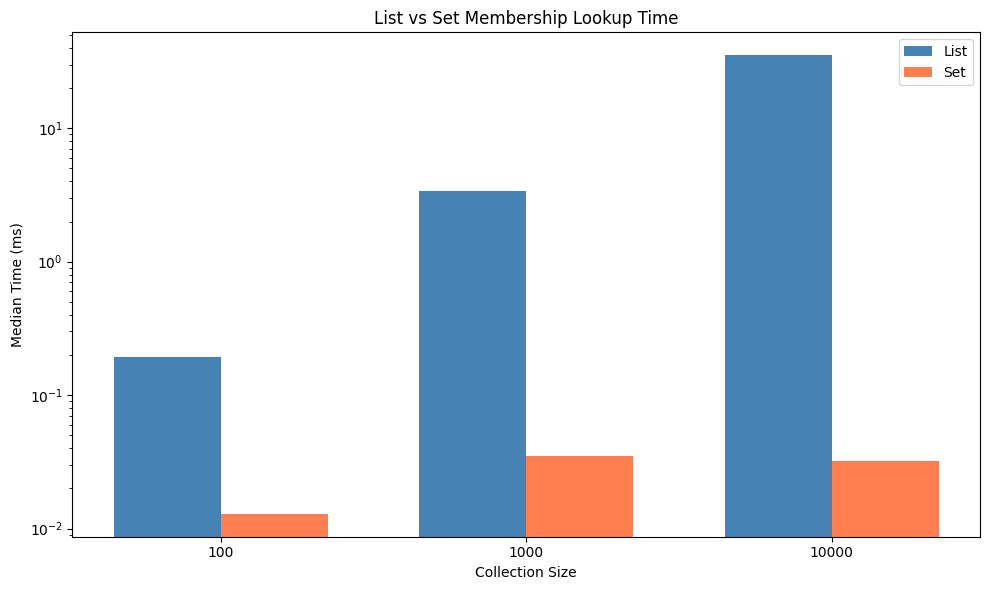

Saved to outputs/benchmark_chart.png


In [7]:
# Create benchmark chart
fig, ax = plt.subplots(figsize=(10, 6))

x = range(len(sizes))
width = 0.35

bars1 = ax.bar([i - width/2 for i in x], timing_df['list_median_ms'], width, label='List', color='steelblue')
bars2 = ax.bar([i + width/2 for i in x], timing_df['set_median_ms'], width, label='Set', color='coral')

ax.set_xlabel('Collection Size')
ax.set_ylabel('Median Time (ms)')
ax.set_title('List vs Set Membership Lookup Time')
ax.set_xticks(x)
ax.set_xticklabels([str(s) for s in sizes])
ax.legend()
ax.set_yscale('log')

plt.tight_layout()
plt.savefig(ROOT / "outputs" / "benchmark_chart.png", dpi=150)
plt.show()
print("Saved to outputs/benchmark_chart.png")

In [8]:
# Memory comparison: lazy vs eager input

# Eager loading (load all lines first)
tracemalloc.start()
all_lines = list(solution.iter_jsonl(ROOT / "data/transactions.jsonl"))
_ = solution.monitor(iter(all_lines))
eager_current, eager_peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

# Lazy loading (process line by line)
tracemalloc.start()
_ = solution.monitor(solution.iter_jsonl(ROOT / "data/transactions.jsonl"))
lazy_current, lazy_peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

memory_results = pd.DataFrame([
    {'method': 'Eager (load all first)', 'peak_kb': eager_peak / 1024},
    {'method': 'Lazy (line by line)', 'peak_kb': lazy_peak / 1024}
])

print("Memory usage comparison (peak Python heap allocations):")
display(memory_results)
print()
print("Note: tracemalloc tracks Python object allocations only.")
print("It does not track memory-mapped files or system allocations.")
print("For small files, the difference is minimal. For large files,")
print("lazy loading avoids storing all lines in memory simultaneously.")

memory_results.to_csv(ROOT / "outputs" / "memory_benchmark.csv", index=False)

Memory usage comparison (peak Python heap allocations):


,method,peak_kb
0,Eager (load all first),42.506836
1,Lazy (line by line),38.157227



Note: tracemalloc tracks Python object allocations only.
It does not track memory-mapped files or system allocations.
For small files, the difference is minimal. For large files,
lazy loading avoids storing all lines in memory simultaneously.


## T5 — Explain choices and limits

1. Show a reference, shallow copy, and deep copy of a nested record.
2. Explain why the first few payments cannot be flagged by this rule.
3. Explain how a flagged large payment can raise the next window mean.
4. Explain arrival order versus event-time order. Suggest one other baseline and its limit.
5. Discuss memory using U = unique valid IDs, A = accounts, W = window size, C = stored categories, O = retained output rows.
6. Explain which parts grow with more input. Small windows do not make the whole program use fixed memory. The seen-ID set and outputs can grow.
7. Suggest a rule for deleting old state. Explain which guarantee changes.

**Example:** deleting old IDs saves memory, but an old repeated ID may then be accepted again.


**Your explanation:**

1. **First payments cannot be flagged**: The anomaly rule requires at least 3 prior values in the window. Until an account has 3 accepted payments, no comparison baseline exists.

2. **Large payments affect future mean**: When a flagged payment (e.g., 22) enters the window [11, 12, 22], the new mean becomes 15. Future payments need to be >= 30 to be flagged, higher than before (22).

3. **Arrival vs event-time order**: We process lines in file order (arrival), not by their `occurred_at` timestamp. This matches real-time stream processing but may miss patterns visible in chronological order.

4. **Alternative baseline**: Use median instead of mean. Limit: More robust to outliers but still influenced by the same window contents.

5. **Memory growth**: 
   - U (unique IDs): O(U) - grows with unique valid transactions
   - A (accounts): O(A * W) - bounded window per account
   - O (output rows): O(anomalies + rejected) - grows unbounded
   - The seen-ID set and output DataFrames can grow without bound.

6. **Old state deletion**: Could expire IDs after a time window. Trade-off: An expired duplicate ID might be accepted again, breaking the uniqueness guarantee.

In [9]:
# T5: Demonstrate reference, shallow copy, and deep copy
import copy

# Nested record
original = {
    'tx_id': 'T1',
    'details': {
        'amounts': [10, 20, 30],
        'meta': {'flagged': False}
    }
}

# Reference (same object)
reference = original

# Shallow copy (new dict, same nested objects)
shallow = copy.copy(original)

# Deep copy (fully independent)
deep = copy.deepcopy(original)

print("Original:", original)
print(f"Reference is original: {reference is original}")
print(f"Shallow is original: {shallow is original}")
print(f"Deep is original: {deep is original}")
print()

# Modify nested object
original['details']['amounts'].append(100)
original['details']['meta']['flagged'] = True

print("After modifying original['details']:")
print(f"  Original amounts: {original['details']['amounts']}")
print(f"  Reference amounts: {reference['details']['amounts']} (same - reference)")
print(f"  Shallow amounts: {shallow['details']['amounts']} (same - shallow copy shares nested objects)")
print(f"  Deep amounts: {deep['details']['amounts']} (unchanged - deep copy is independent)")
print()
print(f"  Original flagged: {original['details']['meta']['flagged']}")
print(f"  Shallow flagged: {shallow['details']['meta']['flagged']} (same nested object)")
print(f"  Deep flagged: {deep['details']['meta']['flagged']} (independent)")

Original: {'tx_id': 'T1', 'details': {'amounts': [10, 20, 30], 'meta': {'flagged': False}}}
Reference is original: True
Shallow is original: False
Deep is original: False

After modifying original['details']:
  Original amounts: [10, 20, 30, 100]
  Reference amounts: [10, 20, 30, 100] (same - reference)
  Shallow amounts: [10, 20, 30, 100] (same - shallow copy shares nested objects)
  Deep amounts: [10, 20, 30] (unchanged - deep copy is independent)

  Original flagged: True
  Shallow flagged: True (same nested object)
  Deep flagged: False (independent)


In [10]:
# Demonstrate how a large payment affects the window mean

window = solution.RollingWindow(3)
for amt in [Decimal("10"), Decimal("11"), Decimal("12")]:
    window.push(amt)

print(f"Before large payment: window = {window.values}, mean = {window.mean}")
print(f"Threshold for anomaly: >= 2 * {window.mean} = {2 * window.mean}")

# Add large payment
window.push(Decimal("22"))
print(f"\nAfter adding 22: window = {window.values}, mean = {window.mean}")
print(f"New threshold: >= 2 * {window.mean} = {2 * window.mean}")
print("\nThe next payment must be >= 30 to be flagged (vs 22 before).")
print("This shows how flagged payments raise the bar for future anomalies.")

Before large payment: window = (Decimal('10'), Decimal('11'), Decimal('12')), mean = 11
Threshold for anomaly: >= 2 * 11 = 22

After adding 22: window = (Decimal('11'), Decimal('12'), Decimal('22')), mean = 15
New threshold: >= 2 * 15 = 30

The next payment must be >= 30 to be flagged (vs 22 before).
This shows how flagged payments raise the bar for future anomalies.


## T6 — Finish and explain your work

Write **800–1,100 words**, excluding tables and code. Save summaries, anomalies, rejected lines, and metrics under `outputs/`. Write Decimal values as strings in JSON. Include the benchmark table and chart, and your extra tests.

Run the notebook from a fresh kernel. Be ready to explain a case selected by the teacher.

Use [SUBMISSION.md](../SUBMISSION.md) for setup and submission. Read [RUBRIC.md](../RUBRIC.md) for marks and [LECTURE_MAP.md](../LECTURE_MAP.md) for lecture sources. Public tests fail until you complete the missing functions. This is expected.


**Your explanation:** See REPORT.md for the full write-up.

In [11]:
# T6: Save outputs with Decimal as strings

def decimal_serializer(obj):
    """Convert Decimal to string for JSON serialization."""
    if isinstance(obj, Decimal):
        return str(obj)
    raise TypeError(f"Object of type {type(obj)} is not JSON serializable")

# Get final results
result = solution.monitor(solution.iter_jsonl(ROOT / "data/transactions.jsonl"))

# Save metrics
with open(ROOT / "outputs" / "metrics.json", "w") as f:
    json.dump(result['metrics'], f, indent=2)
print("Saved metrics.json")

# Save summary (convert Decimal columns to strings)
summary_out = result['summary'].copy()
for col in ['total', 'mean', 'window_mean']:
    if col in summary_out.columns:
        summary_out[col] = summary_out[col].apply(lambda x: str(x) if x is not None else None)
summary_out['window_values'] = summary_out['window_values'].apply(lambda x: [str(v) for v in x] if x else [])
summary_out.to_json(ROOT / "outputs" / "summary.json", orient='records', indent=2)
print("Saved summary.json")

# Save anomalies
anomalies_out = result['anomalies'].copy()
for col in ['amount', 'prior_mean', 'ratio']:
    if col in anomalies_out.columns:
        anomalies_out[col] = anomalies_out[col].apply(lambda x: str(x) if x is not None else None)
anomalies_out.to_json(ROOT / "outputs" / "anomalies.json", orient='records', indent=2)
print("Saved anomalies.json")

# Save rejected
result['rejected'].to_json(ROOT / "outputs" / "rejected.json", orient='records', indent=2)
print("Saved rejected.json")

print("\nAll outputs saved to outputs/ directory.")
print("Files: metrics.json, summary.json, anomalies.json, rejected.json,")
print("       timing_benchmark.csv, memory_benchmark.csv, benchmark_chart.png")

Saved metrics.json
Saved summary.json
Saved anomalies.json
Saved rejected.json

All outputs saved to outputs/ directory.
Files: metrics.json, summary.json, anomalies.json, rejected.json,
       timing_benchmark.csv, memory_benchmark.csv, benchmark_chart.png


In [12]:
# Final summary display
print("="*60)
print("FINAL RESULTS")
print("="*60)
print()
print("Metrics:", result['metrics'])
print()
print("Summary by Account:")
display(result['summary'])
print()
print("Anomalies Detected:")
display(result['anomalies'])
print()
print("Rejected Lines:")
display(result['rejected'])

FINAL RESULTS

Metrics: {'received': 20, 'accepted': 11, 'duplicates': 1, 'rejected': 8}

Summary by Account:


,account,count,total,mean,dominant_category,window_values,window_mean
0,A1,6,168.00,28.00,food,"(22.00, 13.00, 100.00)",45.00
1,A2,5,1.10,0.22,travel,"(0.30, 0.40, 0.10)",0.2666666666666666666666666667



Anomalies Detected:


,line,tx_id,account,amount,prior_mean,ratio
0,5,T4,A1,22.00,11.00,2
1,11,B4,A2,0.40,0.20,2
2,19,T6,A1,100.00,15.66666666666666666666666667,6.382978723404255319148936169



Rejected Lines:


,line,reason
0,7,invalid_event
1,12,invalid_event
2,13,invalid_event
3,14,invalid_event
4,15,invalid_event
5,16,invalid_event
6,17,invalid_event
7,18,invalid_json
